# T15 · Modelo: Regressão Logística (baseline)

**Issue:** #15 · **Fase 3 · Modelagem**

A Regressão Logística é o modelo mais simples e interpretável: cada coeficiente mostra quanto uma variável muda a chance de doença, como nos escores de risco clínicos. É o **baseline**: os outros modelos precisam superá-la para justificar a complexidade.

> Tudo aqui usa só **treino** e **validação**. O teste fica para a T23.
> O modelo está em `src/cardio/models/estimators/logistic.py`; o treino oficial é `python -m cardio.models.train --modelo logistic --features A` (e `B`).

In [1]:
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GridSearchCV

from cardio.config import FIGURES_DIR
from cardio.data.preprocessing import get_cv, load_splits
from cardio.models.estimators.logistic import PARAM_GRID, build_model, odds_ratios

FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def pct(valor: float, casas: int = 1) -> str:
    return f"{valor * 100:.{casas}f}%".replace(".", ",")


def num(valor: float, casas: int = 2) -> str:
    return f"{valor:.{casas}f}".replace(".", ",")


def texto(conteudo: str) -> None:
    display(Markdown(conteudo))

## 1. Escolha dos hiperparâmetros (validação cruzada no treino)

Grid sugerido na issue, com 5 folds estratificados (`get_cv()`) **só no treino**. Métrica de escolha: ROC-AUC; acompanhamos recall e F1.

In [2]:
splits = {fs: load_splits(fs, save_ids=False) for fs in "AB"}
busca = {}
for fs, (X_train, _, _, y_train, _, _) in splits.items():
    gs = GridSearchCV(build_model(X_train), PARAM_GRID, cv=get_cv(), n_jobs=-1, refit="roc_auc",
                      scoring={"roc_auc": "roc_auc", "recall": "recall", "f1": "f1"})
    busca[fs] = gs.fit(X_train, y_train)

tabela_grid = pd.concat([
    pd.DataFrame(gs.cv_results_)[["param_model__C", "param_model__class_weight",
                                  "mean_test_roc_auc", "mean_test_recall", "mean_test_f1"]]
    .assign(conjunto=fs)
    for fs, gs in busca.items()
]).rename(columns=lambda c: c.replace("param_model__", "").replace("mean_test_", ""))
tabela_grid["class_weight"] = tabela_grid["class_weight"].map(lambda v: "nenhum" if v is None else v)
tabela_grid.round(4)

,C,class_weight,roc_auc,recall,f1,conjunto
0,0.01,nenhum,0.7918,0.6680,0.7079,A
1,0.01,balanced,0.7918,0.6747,0.7103,A
2,0.10,nenhum,0.7918,0.6674,0.7074,A
3,0.10,balanced,0.7918,0.6744,0.7102,A
4,1.00,nenhum,0.7918,0.6675,0.7076,A
5,1.00,balanced,0.7918,0.6741,0.7099,A
6,10.00,nenhum,0.7918,0.6675,0.7075,A
7,10.00,balanced,0.7918,0.6742,0.7100,A
0,0.01,nenhum,0.7941,0.6549,0.7042,B
1,0.01,balanced,0.7941,0.6598,0.7060,B


In [3]:
variacao_auc = tabela_grid.groupby("conjunto")["roc_auc"].agg(lambda s: s.max() - s.min())
ganho_recall = (tabela_grid.groupby(["conjunto", "class_weight"])["recall"].mean()
                .unstack().pipe(lambda t: t["balanced"] - t["nenhum"]))
texto(f"""**Interpretação:** o `C` quase não muda a AUC (variação máxima de **{num(variacao_auc.max(), 4)}**):
com 48 mil pacientes e poucas variáveis, a regularização faz pouca diferença. Já `class_weight="balanced"` aumenta o recall em
**{num(ganho_recall["A"] * 100, 1)} p.p.** no conjunto A e **{num(ganho_recall["B"] * 100, 1)} p.p.** no B, sem perder AUC.
O ganho é pequeno porque as classes já são equilibradas (~50% cada), mas vai na direção certa.
Como em triagem o falso negativo é o erro mais grave, o modelo usa **`C=1` e `class_weight="balanced"`** (valores padrão de `build_model()`).""")

**Interpretação:** o `C` quase não muda a AUC (variação máxima de **0,0003**):
com 48 mil pacientes e poucas variáveis, a regularização faz pouca diferença. Já `class_weight="balanced"` aumenta o recall em
**0,7 p.p.** no conjunto A e **0,5 p.p.** no B, sem perder AUC.
O ganho é pequeno porque as classes já são equilibradas (~50% cada), mas vai na direção certa.
Como em triagem o falso negativo é o erro mais grave, o modelo usa **`C=1` e `class_weight="balanced"`** (valores padrão de `build_model()`).

## 2. Resultado na validação: conjunto A × B

In [4]:
linhas, modelos = [], {}
for fs, (X_train, X_val, _, y_train, y_val, _) in splits.items():
    modelo = build_model(X_train)
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    tempo = time.perf_counter() - inicio
    pred, proba = modelo.predict(X_val), modelo.predict_proba(X_val)[:, 1]
    modelos[fs] = modelo
    linhas.append({"conjunto": fs, "n_features": X_train.shape[1], "accuracy": accuracy_score(y_val, pred),
                   "precision": precision_score(y_val, pred), "recall": recall_score(y_val, pred),
                   "f1": f1_score(y_val, pred), "roc_auc": roc_auc_score(y_val, proba), "tempo_s": tempo})
resultado = pd.DataFrame(linhas).set_index("conjunto")
resultado.round(4)

,n_features,accuracy,precision,recall,f1,roc_auc,tempo_s
conjunto,,,,,,,
A,11,0.7267,0.7503,0.6711,0.7085,0.7831,0.2397
B,16,0.7254,0.7579,0.6541,0.7022,0.7851,0.3446


In [5]:
a, b = resultado.loc["A"], resultado.loc["B"]
melhor = "B" if b["roc_auc"] > a["roc_auc"] else "A"
texto(f"""**Interpretação:** os dois conjuntos ficam praticamente empatados: AUC de **{num(a["roc_auc"], 3)}** (A) e
**{num(b["roc_auc"], 3)}** (B), accuracy de {pct(a["accuracy"])} e {pct(b["accuracy"])}, recall de **{pct(a["recall"])}** e
**{pct(b["recall"])}**. As variáveis derivadas do conjunto B (IMC, pressão de pulso, PAM e categorias) quase não ajudam
um modelo linear, porque já são combinações das variáveis originais.

Com o limiar padrão de 0,5, cerca de **{pct(1 - max(a["recall"], b["recall"]), 0)} dos doentes não são sinalizados**.
Isso é o que a **T22** vai tratar, ajustando o limiar na validação.""")

**Interpretação:** os dois conjuntos ficam praticamente empatados: AUC de **0,783** (A) e
**0,785** (B), accuracy de 72,7% e 72,5%, recall de **67,1%** e
**65,4%**. As variáveis derivadas do conjunto B (IMC, pressão de pulso, PAM e categorias) quase não ajudam
um modelo linear, porque já são combinações das variáveis originais.

Com o limiar padrão de 0,5, cerca de **33% dos doentes não são sinalizados**.
Isso é o que a **T22** vai tratar, ajustando o limiar na validação.

## 3. Interpretação: odds ratio (conjunto A)

O odds ratio (`exp(coeficiente)`) é a forma usada em medicina: **1,5** = chance de doença 1,5 vez maior; **0,8** = 20% menor.

> Usamos o conjunto **A**: no B, a pressão de pulso (`ap_hi − ap_lo`) e a PAM são combinações exatas das pressões, então os
> coeficientes se dividem entre variáveis redundantes e deixam de ser interpretáveis individualmente.

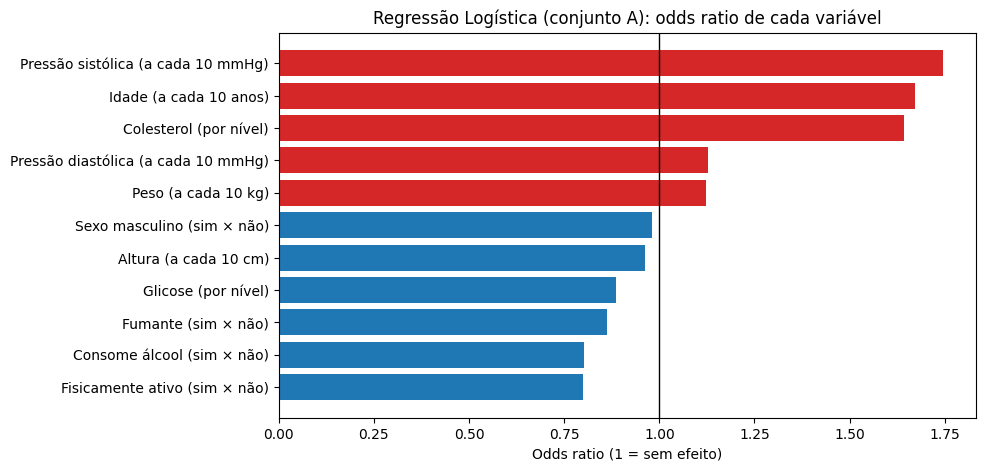

,nome,passo,odds_ratio_no_passo,coeficiente
0,Pressão sistólica,a cada 10 mmHg,1.745,0.931
1,Colesterol,por nível,1.643,0.496
2,Idade,a cada 10 anos,1.672,0.347
3,Fisicamente ativo,sim × não,0.799,-0.224
4,Consome álcool,sim × não,0.803,-0.220
5,Peso,a cada 10 kg,1.124,0.165
6,Fumante,sim × não,0.862,-0.148
7,Glicose,por nível,0.885,-0.122
8,Pressão diastólica,a cada 10 mmHg,1.127,0.113
9,Altura,a cada 10 cm,0.961,-0.031


In [6]:
tabela_or = odds_ratios(modelos["A"])

# Para as contínuas, um passo clinicamente útil (10 mmHg, 10 anos, 10 kg, 10 cm) em vez de 1 unidade
PASSOS = {"ap_hi": (10, "a cada 10 mmHg"), "ap_lo": (10, "a cada 10 mmHg"), "age_years": (10, "a cada 10 anos"),
          "weight": (10, "a cada 10 kg"), "height": (10, "a cada 10 cm")}
NOMES = {"ap_hi": "Pressão sistólica", "ap_lo": "Pressão diastólica", "age_years": "Idade", "weight": "Peso",
         "height": "Altura", "cholesterol": "Colesterol", "gluc": "Glicose", "smoke": "Fumante",
         "alco": "Consome álcool", "active": "Fisicamente ativo", "sex_male": "Sexo masculino"}
tabela_or["passo"] = tabela_or["variavel"].map(lambda v: PASSOS.get(v, (1, "por nível" if v in ("cholesterol", "gluc") else "sim × não"))[1])
tabela_or["odds_ratio_no_passo"] = [
    orr ** PASSOS.get(v, (1,))[0] for v, orr in zip(tabela_or["variavel"], tabela_or["odds_ratio_por_unidade"])
]
tabela_or["nome"] = tabela_or["variavel"].map(NOMES)

fig, ax = plt.subplots(figsize=(9, 5))
ordem = tabela_or.sort_values("odds_ratio_no_passo")
cores = ["tab:red" if v > 1 else "tab:blue" for v in ordem["odds_ratio_no_passo"]]
ax.barh([f"{n} ({p})" for n, p in zip(ordem["nome"], ordem["passo"])], ordem["odds_ratio_no_passo"], color=cores)
ax.axvline(1, color="black", lw=1)
ax.set(title="Regressão Logística (conjunto A): odds ratio de cada variável", xlabel="Odds ratio (1 = sem efeito)")
fig.savefig(FIGURES_DIR / "t15_odds_ratio.png", dpi=120, bbox_inches="tight")
plt.show()

tabela_or[["nome", "passo", "odds_ratio_no_passo", "coeficiente"]].round(3)

In [7]:
o = tabela_or.set_index("variavel")["odds_ratio_no_passo"]
texto(f"""**Interpretação (mantidas as demais variáveis constantes):**

- **Pressão sistólica** é o fator mais forte: a chance de doença fica **{num(o["ap_hi"])} vezes maior a cada 10 mmHg**.
- **Idade**: **{num(o["age_years"])} vezes maior a cada 10 anos**.
- **Colesterol**: **{num(o["cholesterol"])} vezes maior a cada nível** (normal → acima → muito acima).
- **Peso**: {num(o["weight"])} vez a cada 10 kg. Altura e sexo praticamente não têm efeito ({num(o["height"])} e {num(o["sex_male"])}).
- **Atividade física** reduz a chance (odds ratio de {num(o["active"])}), como esperado clinicamente.

**Pontos que pedem cautela (para a discussão crítica, T34):**
- **Fumo ({num(o["smoke"])}) e álcool ({num(o["alco"])})** aparecem como "protetores". Isso não é causal: os hábitos são
  **autodeclarados** (subnotificados) e o dataset é transversal, então quem já tem a doença pode ter mudado de hábito.
- **Glicose ({num(o["gluc"])})** fica abaixo de 1, embora sozinha esteja associada à doença: ela é correlacionada com o colesterol,
  que "absorve" o efeito quando os dois entram juntos no modelo.""")

**Interpretação (mantidas as demais variáveis constantes):**

- **Pressão sistólica** é o fator mais forte: a chance de doença fica **1,75 vezes maior a cada 10 mmHg**.
- **Idade**: **1,67 vezes maior a cada 10 anos**.
- **Colesterol**: **1,64 vezes maior a cada nível** (normal → acima → muito acima).
- **Peso**: 1,12 vez a cada 10 kg. Altura e sexo praticamente não têm efeito (0,96 e 0,98).
- **Atividade física** reduz a chance (odds ratio de 0,80), como esperado clinicamente.

**Pontos que pedem cautela (para a discussão crítica, T34):**
- **Fumo (0,86) e álcool (0,80)** aparecem como "protetores". Isso não é causal: os hábitos são
  **autodeclarados** (subnotificados) e o dataset é transversal, então quem já tem a doença pode ter mudado de hábito.
- **Glicose (0,88)** fica abaixo de 1, embora sozinha esteja associada à doença: ela é correlacionada com o colesterol,
  que "absorve" o efeito quando os dois entram juntos no modelo.

## 4. Parágrafo para o relatório (T32)

In [8]:
tempo_max = resultado["tempo_s"].max()
tempo_txt = "menos de um segundo" if tempo_max < 1 else f"cerca de {num(tempo_max, 1)} segundos"
texto(f"""> **Regressão Logística (baseline).** Modelo linear que estima a probabilidade de doença cardiovascular a partir de uma
> combinação ponderada das variáveis; foi escolhido por ser o mais interpretável (cada coeficiente vira um *odds ratio*, a
> mesma lógica dos escores de risco clínicos) e por servir de referência mínima para os demais modelos. As variáveis
> contínuas são padronizadas (`StandardScaler`) dentro do pipeline. Os hiperparâmetros foram escolhidos por validação cruzada
> de 5 folds no treino: o `C` praticamente não alterou a AUC, e `class_weight="balanced"` aumentou o recall sem perda de AUC,
> por isso o modelo final usa `C=1`, penalidade L2 e `class_weight="balanced"`. Na validação, com o conjunto A, obteve
> accuracy de {pct(a["accuracy"])}, precision de {pct(a["precision"])}, recall de {pct(a["recall"])}, F1 de {pct(a["f1"])} e
> ROC-AUC de {num(a["roc_auc"], 3)}; o conjunto B ficou equivalente (ROC-AUC de {num(b["roc_auc"], 3)}). Os maiores efeitos
> foram da pressão sistólica (odds ratio de {num(o["ap_hi"])} a cada 10 mmHg), da idade ({num(o["age_years"])} a cada 10 anos)
> e do colesterol ({num(o["cholesterol"])} por nível). O treino completo leva {tempo_txt}.""")

> **Regressão Logística (baseline).** Modelo linear que estima a probabilidade de doença cardiovascular a partir de uma
> combinação ponderada das variáveis; foi escolhido por ser o mais interpretável (cada coeficiente vira um *odds ratio*, a
> mesma lógica dos escores de risco clínicos) e por servir de referência mínima para os demais modelos. As variáveis
> contínuas são padronizadas (`StandardScaler`) dentro do pipeline. Os hiperparâmetros foram escolhidos por validação cruzada
> de 5 folds no treino: o `C` praticamente não alterou a AUC, e `class_weight="balanced"` aumentou o recall sem perda de AUC,
> por isso o modelo final usa `C=1`, penalidade L2 e `class_weight="balanced"`. Na validação, com o conjunto A, obteve
> accuracy de 72,7%, precision de 75,0%, recall de 67,1%, F1 de 70,8% e
> ROC-AUC de 0,783; o conjunto B ficou equivalente (ROC-AUC de 0,785). Os maiores efeitos
> foram da pressão sistólica (odds ratio de 1,75 a cada 10 mmHg), da idade (1,67 a cada 10 anos)
> e do colesterol (1,64 por nível). O treino completo leva menos de um segundo.